<a href="https://colab.research.google.com/github/AmolMagar2000/AI-Health-Insurance-Claims-Processing-System/blob/main/Qwen3_1_7B_LoRA_adapter_Finetunning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
%pip -q install -U unsloth datasets scikit-learn rouge-score matplotlib gradio "pandas==2.2.3"

# import pandas as pd

# print("pandas version:", pd.__version__)
# assert pd.__version__ == "2.2.3"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import importlib.metadata as md
import torch

assert torch.cuda.is_available(), "Select a GPU runtime before continuing."
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GiB:",
      round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

for package in [
    "unsloth", "transformers", "trl", "peft", "datasets",
    "torch", "bitsandbytes", "scikit-learn", "gradio"
]:
    print(f"{package}: {md.version(package)}")

GPU: Tesla T4
VRAM GiB: 14.56
unsloth: 2026.10.11
transformers: 5.17.0
trl: 1.15.0
peft: 0.21.2
datasets: 4.8.5
torch: 2.11.0+cu130
bitsandbytes: 0.50.2
scikit-learn: 1.9.1
gradio: 6.31.0


Inspect and split the datasets
We use BANKING77’s published train/test split. Bitext has a train split, so we make our own held-out examples before constructing any training examples. The initial experiment uses a small number per intent to fit a free GPU. The settings below are pilot settings, not a claim of benchmark performance.


In [4]:
from datasets import load_dataset
from collections import Counter

bank = load_dataset("PolyAI/banking77")
bitext = load_dataset(
    "bitext/Bitext-customer-support-llm-chatbot-training-dataset",
    split="train",
)

bank_labels = bank["train"].features["label"].names
bitext_labels = sorted(set(bitext["intent"]))

print("BANKING77 splits:", {k: len(v) for k, v in bank.items()})
print("BANKING77 columns:", bank["train"].column_names)
print("BANKING77 intents:", len(bank_labels))
print("Bitext rows:", len(bitext))
print("Bitext columns:", bitext.column_names)
print("Bitext intents:", len(bitext_labels))
print("Example BANKING77:", bank["train"][0])
print("Example Bitext:", bitext[0])

README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

... (2 outputs left out)

Bitext_Sample_Customer_Support_Training_(…): reconstructing file:   0%|          |  0.00B / 19.2MB            

Bitext_Sample_Customer_Support_Training_(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/26872 [00:00<?, ? examples/s]

BANKING77 splits: {'train': 10003, 'test': 3080}
BANKING77 columns: ['text', 'label']
BANKING77 intents: 77
Bitext rows: 26872
Bitext columns: ['flags', 'instruction', 'category', 'intent', 'response']
Bitext intents: 27
Example BANKING77: {'text': 'I am still waiting on my card?', 'label': 11}
Example Bitext: {'flags': 'B', 'instruction': 'question about cancelling order {{Order Number}}', 'category': 'ORDER', 'intent': 'cancel_order', 'response': "I've understood you have a question regarding canceling order {{Order Number}}, and I'm here to provide you with the information you need. Please go ahead and ask your question, and I'll do my best to assist you."}


Small, reproducible, disjoint subsets

**Why split first? **If the same Bitext row supplied a training response and an evaluation question, the evaluation would reward memorization. Even with row separation, Bitext has repeated patterns and placeholders, so this pilot evaluation is not a substitute for testing on real, independently written customer requests.

In [5]:
import random
from collections import defaultdict

SEED = 42
BANK_TRAIN_PER_INTENT = 12
BANK_TEST_PER_INTENT = 1
BITEXT_TRAIN_PER_INTENT = 30
BITEXT_TEST_PER_INTENT = 1

rng = random.Random(SEED)

def grouped_indices(ds, key):
    groups = defaultdict(list)
    for i, row in enumerate(ds):
        groups[key(row)].append(i)
    return groups

bank_train_groups = grouped_indices(
    bank["train"], lambda row: bank_labels[row["label"]]
)
bank_test_groups = grouped_indices(
    bank["test"], lambda row: bank_labels[row["label"]]
)
bitext_groups = grouped_indices(bitext, lambda row: row["intent"])

bank_train_ids, bank_test_ids = [], []
bitext_train_ids, bitext_test_ids = [], []

for label in bank_labels:
    a = bank_train_groups[label][:]
    b = bank_test_groups[label][:]
    rng.shuffle(a)
    rng.shuffle(b)
    assert len(a) >= BANK_TRAIN_PER_INTENT
    assert len(b) >= BANK_TEST_PER_INTENT
    bank_train_ids.extend(a[:BANK_TRAIN_PER_INTENT])
    bank_test_ids.extend(b[:BANK_TEST_PER_INTENT])

for label in bitext_labels:
    ids = bitext_groups[label][:]
    rng.shuffle(ids)
    needed = BITEXT_TRAIN_PER_INTENT + BITEXT_TEST_PER_INTENT
    assert len(ids) >= needed, (label, len(ids))
    bitext_test_ids.extend(ids[:BITEXT_TEST_PER_INTENT])
    bitext_train_ids.extend(ids[BITEXT_TEST_PER_INTENT:needed])

bank_train = bank["train"].select(bank_train_ids)
bank_test = bank["test"].select(bank_test_ids)
bitext_train = bitext.select(bitext_train_ids)
bitext_test = bitext.select(bitext_test_ids)

print({
    "bank_train": len(bank_train),
    "bank_test": len(bank_test),
    "bitext_train": len(bitext_train),
    "bitext_test": len(bitext_test),
})

{'bank_train': 924, 'bank_test': 77, 'bitext_train': 810, 'bitext_test': 27}


2. Load the original model and define the tasks
Qwen3 supports a non-thinking mode, useful here for short, directly measurable intent names and support replies. We apply the same chat template and generation settings before and after training.

In [6]:
from unsloth import FastLanguageModel

MODEL_ID = "Qwen/Qwen3-1.7B"
MAX_LENGTH = 768

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=MODEL_ID,
    max_seq_length=MAX_LENGTH,
    dtype=None,             # Unsloth selects a suitable GPU dtype
    load_in_4bit=True,
)

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

print("EOS token:", repr(tokenizer.eos_token))
print("Padding token:", repr(tokenizer.pad_token))

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.10.11: Fast Qwen3 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

EOS token: '<|im_end|>'
Padding token: '<|vision_pad|>'


A T4 typically uses FP16 computation with 4-bit stored weights. The 4-bit setting describes storage of the frozen model, not 4-bit LoRA gradients.

Define consistent prompts and inference

In [7]:
CLASSIFY_SYSTEM = (
    "You classify customer support messages. Return exactly one intent "
    "label in snake_case. Return only the label, with no explanation."
)

REPLY_SYSTEM = (
    "You are a professional customer support assistant. Give a concise, "
    "helpful response with a clear next step. Do not claim that you checked "
    "an account, completed an action, or verified a transaction. Do not "
    "invent company policies, phone numbers, timelines, or fees. Preserve "
    "any placeholders in the customer request."
)

def user_text(task, message):
    if task == "bank_intent":
        return (
            "Task: BANKING77 intent classification.\n"
            f"Customer message: {message}\n"
            "Return the BANKING77 intent label:"
        )
    if task == "bitext_intent":
        return (
            "Task: Bitext customer-support intent classification.\n"
            f"Customer message: {message}\n"
            "Return the Bitext intent label:"
        )
    if task == "reply":
        return (
            "Task: Write a customer-support response.\n"
            f"Customer message: {message}\n"
            "Response:"
        )
    raise ValueError(task)

def make_prompt(task, message):
    system = REPLY_SYSTEM if task == "reply" else CLASSIFY_SYSTEM
    return tokenizer.apply_chat_template(
        [
            {"role": "system", "content": system},
            {"role": "user", "content": user_text(task, message)},
        ],
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False,
    )

def predict(task, message, seed):
    FastLanguageModel.for_inference(model)
    prompt = make_prompt(task, message)
    encoded = tokenizer(
        prompt, return_tensors="pt", add_special_tokens=False
    ).to("cuda")

    torch.manual_seed(seed)
    with torch.inference_mode():
        output = model.generate(
            **encoded,
            max_new_tokens=24 if task != "reply" else 160,
            do_sample=True,
            temperature=0.7,
            top_p=0.8,
            top_k=20,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    generated = output[0, encoded["input_ids"].shape[1]:]
    return tokenizer.decode(generated, skip_special_tokens=True).strip()

Tokenization turns text into token IDs. The chat template adds Qwen’s role boundaries and opens the assistant turn. During evaluation, we decode only newly generated tokens. We seed every example individually, so the two evaluations use the same sampling configuration and per-example random seed. Sampling still means results can vary across different GPU/software environments.

**3. Evaluate the untouched model first**
Store the generated strings before attaching LoRA. We will reuse precisely these test records after training.

In [8]:
test_cases = []

for i, row in enumerate(bank_test):
    test_cases.append({
        "id": f"bank-{i}",
        "task": "bank_intent",
        "message": row["text"],
        "reference": bank_labels[row["label"]],
    })

for i, row in enumerate(bitext_test):
    test_cases.append({
        "id": f"bitext-intent-{i}",
        "task": "bitext_intent",
        "message": row["instruction"],
        "reference": row["intent"],
    })
    test_cases.append({
        "id": f"bitext-reply-{i}",
        "task": "reply",
        "message": row["instruction"],
        "reference": row["response"],
    })

print("Fixed test cases:", len(test_cases))
print(Counter(x["task"] for x in test_cases))

Fixed test cases: 131
Counter({'bank_intent': 77, 'bitext_intent': 27, 'reply': 27})


Generate and save the base-model outputs

In [10]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

OUT = Path("/content/drive/MyDrive/customer_support_experiment")
OUT.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [11]:
import json
from pathlib import Path
from tqdm.auto import tqdm

OUT = Path("/content/customer_support_experiment")
OUT.mkdir(exist_ok=True)

def run_test(stage):
    records = []
    for i, case in enumerate(tqdm(test_cases, desc=stage)):
        records.append({
            **case,
            "prediction": predict(case["task"], case["message"], SEED + i),
            "stage": stage,
        })
    path = OUT / f"{stage}_predictions.jsonl"
    with path.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    print("Saved:", path)
    return records

before = run_test("before")
print(json.dumps(before[:3], indent=2, ensure_ascii=False))

before:   0%|          | 0/131 [00:00<?, ?it/s]

Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Saved: /content/customer_support_experiment/before_predictions.jsonl
[
  {
    "id": "bank-0",
    "task": "bank_intent",
    "message": "Assist me please with card activation.",
    "reference": "activate_my_card",
    "prediction": "banking77",
    "stage": "before"
  },
  {
    "id": "bank-1",
    "task": "bank_intent",
    "message": "I would like an account for my children, how do I go about doing this?",
    "reference": "age_limit",
    "prediction": "account_opening",
    "stage": "before"
  },
  {
    "id": "bank-2",
    "task": "bank_intent",
    "message": "how do i add money with my apple watch",
    "reference": "apple_pay_or_google_pay",
    "prediction": "banking77",
    "stage": "before"
  }
]


4. Construct the multi-task training set
Each example has a prompt and completion. For Bitext, the same training row creates a classification example and a response example; that is legitimate because both targets are supplied in the row. Test rows create neither.

**Cell 9 — Format the targets**

In [12]:
from datasets import Dataset

train_rows = []

def add_example(task, message, target):
    train_rows.append({
        "prompt": make_prompt(task, message),
        "completion": str(target).strip() + tokenizer.eos_token,
    })

for row in bank_train:
    add_example(
        "bank_intent",
        row["text"],
        bank_labels[row["label"]],
    )

for row in bitext_train:
    add_example("bitext_intent", row["instruction"], row["intent"])
    add_example("reply", row["instruction"], row["response"])

random.Random(SEED).shuffle(train_rows)
train_ds = Dataset.from_list(train_rows)

print("Training examples:", len(train_ds))
print("Prompt preview:", train_ds[0]["prompt"][-400:])
print("Completion preview:", train_ds[0]["completion"][:250])

def lengths(example):
    full = example["prompt"] + example["completion"]
    return len(tokenizer(full, add_special_tokens=False)["input_ids"])

sample_lengths = [lengths(train_ds[i]) for i in range(min(300, len(train_ds)))]
print("Sample token lengths: median =", sorted(sample_lengths)[len(sample_lengths)//2])
print("Sample token lengths: max =", max(sample_lengths))

Training examples: 2544
Prompt preview: <|im_start|>system
You classify customer support messages. Return exactly one intent label in snake_case. Return only the label, with no explanation.<|im_end|>
<|im_start|>user
Task: BANKING77 intent classification.
Customer message: How does one send me money?
Return the BANKING77 intent label:<|im_end|>
<|im_start|>assistant
<think>

</think>


Completion preview: receiving_money<|im_end|>
Sample token lengths: median = 78
Sample token lengths: max = 440


Why completion-only loss? We want to teach the desired label or response, not spend training capacity predicting the repeated system instructions and customer prompt. max_length=768 truncates long examples; inspect the printed lengths and increase it only if GPU memory permits. Long Bitext responses may be truncated in this small pilot.

**5. Attach LoRA and train**

Cell 10 — Add trainable LoRA matrices

In [13]:
model = FastLanguageModel.get_peft_model(
    model,
    r=16,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj",
    ],
    lora_alpha=16,
    lora_dropout=0,
    bias="none",
    use_gradient_checkpointing="unsloth",
    random_state=SEED,
)

model.print_trainable_parameters()

Unsloth 2026.10.11 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen3DecoderLayer).
trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


r=16 controls the low-rank adapter size. Larger ranks can represent more changes but increase trainable parameters and memory. Gradient checkpointing recomputes some intermediate activations during backward propagation to save memory.

**Cell 11 Supervised fine-tuning**

In [14]:
from trl import SFTConfig, SFTTrainer

args = SFTConfig(
    output_dir=str(OUT / "checkpoints"),
    max_length=MAX_LENGTH,
    completion_only_loss=True,
    packing=False,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    max_steps=180,
    learning_rate=2e-4,
    warmup_steps=10,
    lr_scheduler_type="linear",
    optim="adamw_8bit",
    fp16=not torch.cuda.is_bf16_supported(),
    bf16=torch.cuda.is_bf16_supported(),
    gradient_checkpointing=True,
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)

trainer = SFTTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    processing_class=tokenizer,
)

# Verify that TRL masks the prompt rather than silently training on it.
prepared = trainer.train_dataset[0]
print("Prepared columns:", trainer.train_dataset.column_names)
if "completion_mask" in prepared:
    print("Masked prompt tokens:", prepared["completion_mask"].count(0))
    assert 0 in prepared["completion_mask"]
    assert 1 in prepared["completion_mask"]

train_result = trainer.train()
print(train_result)

Unsloth: Tokenizing ["prompt"+"completion"] (num_proc=2):   0%|          | 0/2544 [00:00<?, ? examples/s]

Unsloth: Building labels for train dataset (num_proc=2):   0%|          | 0/2544 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.
Prepared columns: ['input_ids', 'labels']


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 2,544 | Num Epochs = 1 | Total steps = 180
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 17,432,576 of 1,738,007,552 (1.00% trained)


Step,Training Loss
10,2.898360
20,1.754432
30,1.374544
40,1.255116
50,1.208487
60,1.087065
70,1.158847
80,1.056805
90,1.071641
100,1.057131


TrainOutput(global_step=180, training_loss=1.1959181891547308, metrics={'train_runtime': 491.3493, 'train_samples_per_second': 2.931, 'train_steps_per_second': 0.366, 'total_flos': 1521102701426688.0, 'train_loss': 1.1959181891547308, 'epoch': 0.5660377358490566})


In [15]:
ADAPTER_DIR = OUT / "qwen3_customer_support_lora"

model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))

print("Trained adapter saved to:", ADAPTER_DIR)

Unsloth: Restored added_tokens_decoder metadata in /content/customer_support_experiment/qwen3_customer_support_lora/tokenizer_config.json.


Trained adapter saved to: /content/customer_support_experiment/qwen3_customer_support_lora


**6. Evaluate the fine-tuned model on the identical examples**
Cell 12 — Generate and save the after outputs

In [16]:
after = run_test("after")

assert [x["id"] for x in before] == [x["id"] for x in after]
assert [x["reference"] for x in before] == [x["reference"] for x in after]

after:   0%|          | 0/131 [00:00<?, ?it/s]

Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generati

Saved: /content/customer_support_experiment/after_predictions.jsonl


**Cell 13  Accuracy, macro F1, and ROUGE**

In [17]:
from sklearn.metrics import accuracy_score, f1_score
from rouge_score import rouge_scorer
import pandas as pd

rouge = rouge_scorer.RougeScorer(
    ["rouge1", "rougeL"], use_stemmer=True
)

def evaluate(records, stage):
    result = []
    for task, allowed in [
        ("bank_intent", bank_labels),
        ("bitext_intent", bitext_labels),
    ]:
        subset = [x for x in records if x["task"] == task]
        truth = [x["reference"] for x in subset]
        # Strip whitespace only. Invalid or explanatory outputs count as wrong.
        pred = [x["prediction"].strip() for x in subset]
        result.extend([
            {
                "stage": stage, "task": task,
                "metric": "accuracy",
                "value": accuracy_score(truth, pred),
                "n": len(subset),
            },
            {
                "stage": stage, "task": task,
                "metric": "macro_f1",
                "value": f1_score(
                    truth, pred, labels=list(allowed),
                    average="macro", zero_division=0
                ),
                "n": len(subset),
            },
            {
                "stage": stage, "task": task,
                "metric": "valid_label_rate",
                "value": sum(p in allowed for p in pred) / len(pred),
                "n": len(subset),
            },
        ])

    replies = [x for x in records if x["task"] == "reply"]
    scores = [
        rouge.score(x["reference"], x["prediction"])
        for x in replies
    ]
    for name in ["rouge1", "rougeL"]:
        result.append({
            "stage": stage, "task": "reply",
            "metric": f"{name}_f1",
            "value": sum(s[name].fmeasure for s in scores) / len(scores),
            "n": len(replies),
        })
    return result

metrics = pd.DataFrame(
    evaluate(before, "before") + evaluate(after, "after")
)
comparison = metrics.pivot(
    index=["task", "metric", "n"],
    columns="stage",
    values="value",
).reset_index()
comparison["change"] = comparison["after"] - comparison["before"]

display(comparison.round(3))
comparison.to_csv(OUT / "metrics_comparison.csv", index=False)

stage,task,metric,n,after,before,change
0,bank_intent,accuracy,77,0.195,0.000,0.195
1,bank_intent,macro_f1,77,0.186,0.000,0.186
2,bank_intent,valid_label_rate,77,0.364,0.013,0.351
3,bitext_intent,accuracy,27,0.815,0.000,0.815
4,bitext_intent,macro_f1,27,0.790,0.000,0.790
5,bitext_intent,valid_label_rate,27,0.889,0.000,0.889
6,reply,rouge1_f1,27,0.483,0.289,0.194
7,reply,rougeL_f1,27,0.314,0.185,0.129


Interpretation: Accuracy measures exact intent matches. Macro F1 gives each intent equal weight; with only one held-out example per intent, its estimate is noisy. ROUGE measures word overlap with Bitext’s supplied response, not factual correctness, safety, or customer usefulness. A concise good answer can score below a longer templated one.


**Cell 14  Show actual paired predictions**

In [18]:
pairs = pd.DataFrame([
    {
        "task": b["task"],
        "customer": b["message"],
        "reference": b["reference"],
        "base_model": b["prediction"],
        "fine_tuned": a["prediction"],
    }
    for b, a in zip(before, after)
])

display(
    pd.concat([
        pairs[pairs.task == "bank_intent"].head(3),
        pairs[pairs.task == "bitext_intent"].head(3),
        pairs[pairs.task == "reply"].head(5),
    ], ignore_index=True)
)
pairs.to_csv(OUT / "paired_predictions.csv", index=False)

,task,customer,reference,base_model,fine_tuned
0,bank_intent,Assist me please with card activation.,activate_my_card,banking77,card_swallowed
1,bank_intent,"I would like an account for my children, how d...",age_limit,account_opening,create_account
2,bank_intent,how do i add money with my apple watch,apple_pay_or_google_pay,banking77,top_up_by_apple_pay
3,bitext_intent,is it possible to cancel purchase {{Order Numb...,cancel_order,cancel_purchase,cancel_order
4,bitext_intent,can I swap some items of purchase {{Order Numb...,change_order,order_number,change_order
5,bitext_intent,can you give me information about editibg the ...,change_shipping_address,address_editing,edit_shipping_address
6,reply,is it possible to cancel purchase {{Order Numb...,I've been informed that you're wondering if it...,We apologize for the inconvenience. Please con...,Thank you for your inquiry about the possibili...
7,reply,can I swap some items of purchase {{Order Numb...,Your message means a lot! I'm aligned with the...,We appreciate your request. Please check the s...,We're thrilled to hear that you're interested ...
8,reply,can you give me information about editibg the ...,Unquestionably! If you need to edit your addre...,"Sure, I’d be happy to help with that. Could yo...",I appreciate your inquiry about editing the ad...
9,reply,I want help seeing the withdrawal penalties,Sure! I can assist you with viewing the withdr...,We're sorry to hear you're looking for help wi...,I've noticed that you're interested in seeing ...


**Cell 15 — Plot the measured changes**

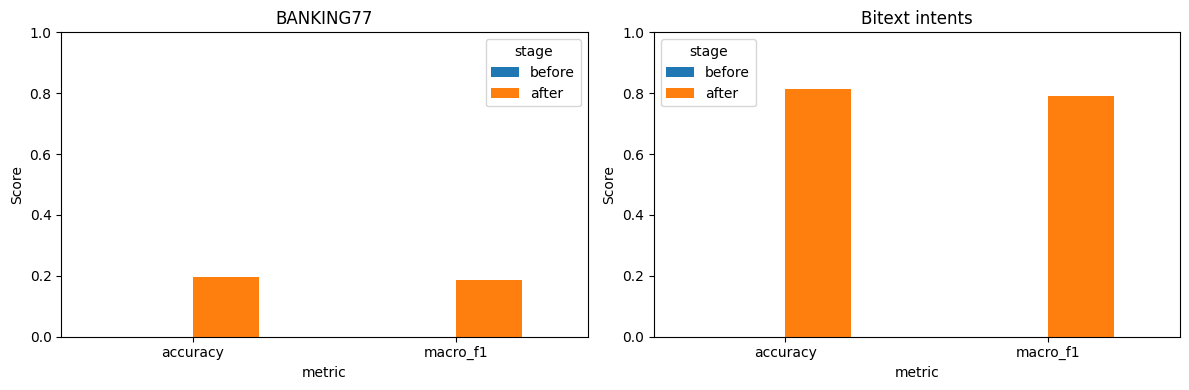

stage,metric,before,after,change
6,rouge1_f1,0.289,0.483,0.194
7,rougeL_f1,0.185,0.314,0.129


In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, task, title in [
    (axes[0], "bank_intent", "BANKING77"),
    (axes[1], "bitext_intent", "Bitext intents"),
]:
    part = metrics[
        (metrics.task == task) &
        (metrics.metric.isin(["accuracy", "macro_f1"]))
    ]
    pivot = part.pivot(index="metric", columns="stage", values="value")
    pivot[["before", "after"]].plot.bar(ax=ax, rot=0)
    ax.set_title(title)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")

plt.tight_layout()
plt.show()

display(
    comparison[comparison.task == "reply"][
        ["metric", "before", "after", "change"]
    ].round(3)
)

In [20]:
review = pairs[pairs.task == "reply"].sample(
    n=min(10, sum(pairs.task == "reply")),
    random_state=SEED,
).copy()

review["base_helpfulness_1_to_5"] = ""
review["tuned_helpfulness_1_to_5"] = ""
review["base_unsupported_claim"] = ""
review["tuned_unsupported_claim"] = ""
review["notes"] = ""

review_path = OUT / "human_review_template.csv"
review.to_csv(review_path, index=False)
display(review)
print("Review sheet:", review_path)

,task,customer,reference,base_model,fine_tuned,base_helpfulness_1_to_5,tuned_helpfulness_1_to_5,base_unsupported_claim,tuned_unsupported_claim,notes
94,reply,I don't know what to do to talk to customer se...,Thank you for trusting us! I'm fully aware of ...,We're sorry you're having trouble reaching cus...,I understand that you're unsure of what to do ...,,,,,
104,reply,want assistance to see how soon can I expect m...,We understand your eagerness to receive your p...,We're sorry to hear you're looking to track yo...,I'm on the same page with you! I understand th...,,,,,
96,reply,I need assistance to talk tl an agent,We're listening! I'm keyed into the fact that ...,We're sorry to hear you need assistance. Pleas...,I'm here to help! I'm glad you reached out to ...,,,,,
120,reply,i want help to notify of a problem with sign-up,Thank you for seeking assistance in notifying ...,We're sorry to hear you're having trouble with...,I'm here to assist you in notifying us about t...,,,,,
78,reply,is it possible to cancel purchase {{Order Numb...,I've been informed that you're wondering if it...,We apologize for the inconvenience. Please con...,Thank you for your inquiry about the possibili...,,,,,
100,reply,find information about the cancellation of my ...,Glad you got in touch to us to find informatio...,We understand your request and are working to ...,I'm here to help you with finding information ...,,,,,
110,reply,I am trying to get rebates of money,I can relate that you're making an effort to o...,We appreciate your interest in maximizing your...,I apologize for any inconvenience you may have...,,,,,
112,reply,wanna unsubscribe from the corporate newsletter,I'm sorry to hear that you would like to unsub...,Thank you for letting us know. To unsubscribe ...,Thank you for your interest in unsubscribing f...,,,,,
102,reply,i want help to see what methods for delivery a...,"Ah, I'm excited to assist you in exploring our...",We're sorry to hear you're looking for help. C...,We're here to assist you! I understand that yo...,,,,,
126,reply,need assistance to switch to the {{Account Typ...,Thank you for trusting to us with your request...,We’re sorry to hear you need assistance with s...,I've noticed that you're looking to switch to ...,,,,,


Review sheet: /content/customer_support_experiment/human_review_template.csv


For each response, score whether it addresses the question, gives an actionable next step, stays professional, preserves placeholders, and avoids unsupported claims. Fill this CSV manually; code cannot honestly manufacture these judgments. In particular, check claims that an account was accessed, a refund was issued, or an order was cancelled.

**7. Save, reload, and try your own questions**

In [21]:
ADAPTER_DIR = OUT / "qwen3_customer_support_lora"
model.save_pretrained(str(ADAPTER_DIR))
tokenizer.save_pretrained(str(ADAPTER_DIR))

config = {
    "base_model": MODEL_ID,
    "max_length": MAX_LENGTH,
    "seed": SEED,
    "bank_train_per_intent": BANK_TRAIN_PER_INTENT,
    "bank_test_per_intent": BANK_TEST_PER_INTENT,
    "bitext_train_per_intent": BITEXT_TRAIN_PER_INTENT,
    "bitext_test_per_intent": BITEXT_TEST_PER_INTENT,
    "max_steps": args.max_steps,
}
(OUT / "experiment_config.json").write_text(
    json.dumps(config, indent=2), encoding="utf-8"
)

print("Adapter:", ADAPTER_DIR)
print("Saved files:", [p.name for p in OUT.iterdir()])

Adapter: /content/customer_support_experiment/qwen3_customer_support_lora
Saved files: ['checkpoints', 'human_review_template.csv', 'qwen3_customer_support_lora', 'before_predictions.jsonl', 'experiment_config.json', 'paired_predictions.csv', 'after_predictions.jsonl', 'metrics_comparison.csv']


The adapter is not a standalone full model: reload it with the same base model. Colab’s /content is temporary. To retain everything across sessions, optionally run:

In [22]:
from google.colab import drive
drive.mount("/content/drive")

import shutil
destination = "/content/drive/MyDrive/customer_support_experiment"
shutil.copytree(OUT, destination, dirs_exist_ok=True)
print("Copied to:", destination)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Copied to: /content/drive/MyDrive/customer_support_experiment


In [23]:
questions = [
    ("bank_intent", "I lost my debit card yesterday. What should I do?"),
    ("bitext_intent", "Can I cancel my order?"),
    ("reply", "My payment failed, but I can see a charge. What should I do?"),
]

for i, (task, question) in enumerate(questions):
    print("\nTASK:", task)
    print("CUSTOMER:", question)
    print("MODEL:", predict(task, question, SEED + 10_000 + i))

Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



TASK: bank_intent
CUSTOMER: I lost my debit card yesterday. What should I do?


Both `max_new_tokens` (=24) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


MODEL: card_lost_or_stolen

TASK: bitext_intent
CUSTOMER: Can I cancel my order?


Both `max_new_tokens` (=160) and `max_length`(=40960) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


MODEL: cancel_order

TASK: reply
CUSTOMER: My payment failed, but I can see a charge. What should I do?
MODEL: I apologize for the inconvenience caused by the failed payment. It's unfortunate that you are unable to see the charge, but please rest assured that we are aware of the issue and are working to resolve it. To proceed, please provide us with the details of the failed payment, such as the payment method used, the date and time of the payment, and any error messages or codes received. This information will help us investigate the problem and assist you in resolving it. Thank you for bringing this to our attention, and we appreciate your patience as we work together to ensure a smooth payment process for you.


In [24]:
import gradio as gr

def demo(message, task):
    if not message.strip():
        return ""
    return predict(task, message, SEED + 20_000)

app = gr.Interface(
    fn=demo,
    inputs=[
        gr.Textbox(label="Customer message", lines=3),
        gr.Dropdown(
            choices=["bank_intent", "bitext_intent", "reply"],
            value="reply",
            label="Task",
        ),
    ],
    outputs=gr.Textbox(label="Model output", lines=6),
    title="Multi-Task Customer Support Assistant — Qwen3-1.7B QLoRA",
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://47774046a21abe434a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [25]:
from pathlib import Path

saved = Path("/content/drive/MyDrive/customer_support_experiment/qwen3_customer_support_lora")
for name in ["adapter_config.json", "adapter_model.safetensors", "tokenizer_config.json"]:
    p = saved / name
    print(name, "OK" if p.is_file() and p.stat().st_size > 0 else "MISSING")


adapter_config.json OK
adapter_model.safetensors OK
tokenizer_config.json OK
